# Day 06: Data Preprocessing and Feature Engineering

## Project: Titanic Survival Prediction

### Project Overview
This project focuses on building a reusable data preprocessing pipeline using Python and Scikit-learn.

The main goal is to prepare raw data for machine learning by handling missing values, encoding categorical features and scaling numerical features.

### Objectives
- Identify and handle missing values.
- Apply numerical and categorical preprocessing.
- Perform feature encoding and scaling.
- Use ColumnTransformer and Pipeline.
- Prevent data leakage during preprocessing.
- Compare baseline and full preprocessing models.
- Build and save a reusable machine learning pipeline.

### Dataset
Titanic Dataset

- Total Records: 891
- Total Columns: 12
- Target Variable: Survived

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

### Expected Outcome
A reusable preprocessing pipeline that can transform raw data and prepare it for machine learning.

## 1. Importing Required Libraries

In [42]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# System and file handling
from pathlib import Path
import sys
import joblib

# Machine learning preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model training
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

In [43]:
# Set project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Add project directory to Python path
sys.path.insert(0, str(PROJECT_DIR))

# Import project modules
from src.data_loader import load_data, prepare_features_target

# Load dataset
df = load_data()

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Dataset Overview

In [44]:
# Display dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Number of Rows: 891
Number of Columns: 12

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [45]:
# Generate statistical summary
print("Statistical Summary:")
display(df.describe(include="all"))

Statistical Summary:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


## 4. Missing Value Analysis

In [46]:
# Calculate missing values and percentages
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_values)

,Missing Values,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


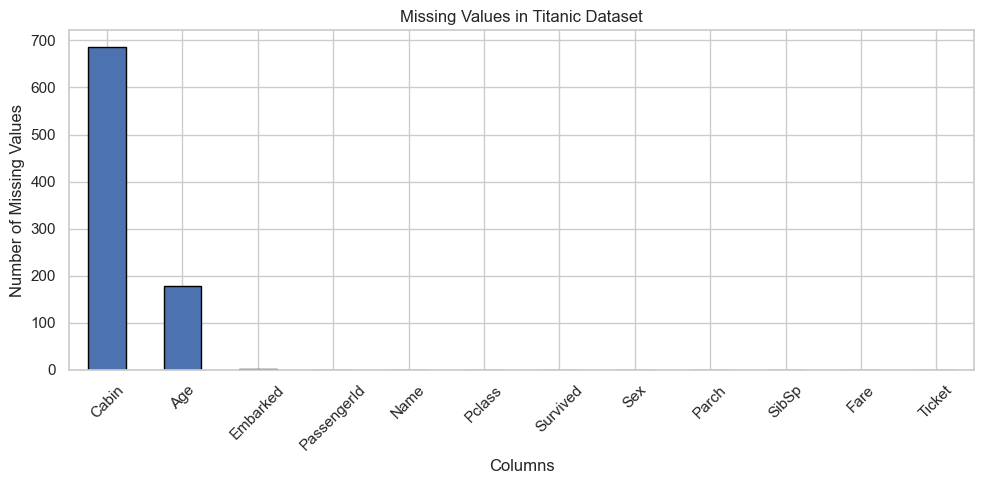

Missing values graph saved successfully!


In [47]:
# Create figures directory
figures_dir = PROJECT_DIR / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Visualize missing values
plt.figure(figsize=(10, 5))

missing_values["Missing Values"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()

# Save graph
plt.savefig(
    figures_dir / "missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

# Display graph
plt.show()

print("Missing values graph saved successfully!")

## 5. Feature Selection

In [48]:
# Separate input features and target variable
X, y = prepare_features_target(df)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

Input Features Shape: (891, 7)
Target Shape: (891,)

Selected Input Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S



Target Variable:


0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

## 6. Train-Test Split

In [49]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 7)
Testing Features: (179, 7)
Training Target: (712,)
Testing Target: (179,)


## 7. Data Preprocessing Techniques

Data preprocessing converts raw data into a suitable format for machine learning.

The following techniques are used:

### 1. Imputation
Missing numerical values are replaced using the median, while missing categorical values are replaced using the most frequent value.

### 2. One-Hot Encoding
Categorical values are converted into numerical columns so that machine learning algorithms can process them.

### 3. Standard Scaling
Numerical features are transformed to have a mean of approximately 0 and a standard deviation of approximately 1.

### 4. ColumnTransformer
It applies different preprocessing operations to numerical and categorical features.

### 5. Pipeline
It combines multiple preprocessing and machine learning steps into one reusable workflow.

## 8. Baseline Preprocessing

In [50]:
# Define numerical and categorical features
numerical_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

# Numerical preprocessing
baseline_numerical = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
baseline_categorical = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
baseline_preprocessor = ColumnTransformer(
    transformers=[
        ("num", baseline_numerical, numerical_features),
        ("cat", baseline_categorical, categorical_features)
    ]
)

print("Baseline Preprocessor Created Successfully!")

Baseline Preprocessor Created Successfully!


## 9. Full Preprocessing Pipeline

In [51]:
# Import reusable preprocessing function
from src.preprocessing import create_preprocessor

# Create full preprocessing pipeline
full_preprocessor = create_preprocessor()

print("Full Preprocessing Pipeline Created Successfully!")

Full Preprocessing Pipeline Created Successfully!


## 10. Model Training

In [52]:
# Create baseline model
baseline_model = Pipeline(steps=[
    ("preprocessor", baseline_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train baseline model
baseline_model.fit(X_train, y_train)

# Create full preprocessing model
full_model = Pipeline(steps=[
    ("preprocessor", full_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train full model
full_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## 11. Model Evaluation

In [53]:
# Generate predictions
baseline_predictions = baseline_model.predict(X_test)
full_predictions = full_model.predict(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
full_accuracy = accuracy_score(y_test, full_predictions)

# Create comparison table
comparison = pd.DataFrame({
    "Model": [
        "Baseline (Imputation + Encoding)",
        "Full Pipeline (Imputation + Encoding + Scaling)"
    ],
    "Accuracy": [
        baseline_accuracy,
        full_accuracy
    ]
})

display(comparison)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Full Pipeline Accuracy: {full_accuracy:.4f}")

,Model,Accuracy
0,Baseline (Imputation + Encoding),0.804469
1,Full Pipeline (Imputation + Encoding + Scaling),0.804469


Baseline Accuracy: 0.8045
Full Pipeline Accuracy: 0.8045


In [54]:
# Display classification report
print("FULL PIPELINE CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        full_predictions
    )
)

FULL PIPELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



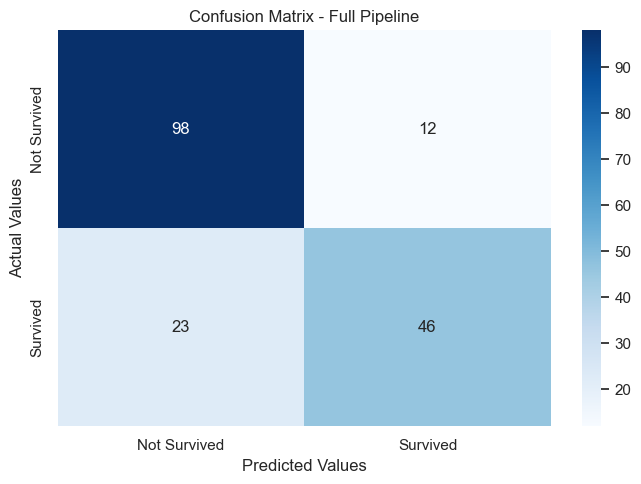

Confusion matrix graph saved successfully!


In [55]:
# Create figures directory
figures_dir = PROJECT_DIR / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Generate confusion matrix
cm = confusion_matrix(y_test, full_predictions)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Confusion Matrix - Full Pipeline")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()

# Save graph
plt.savefig(
    figures_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix graph saved successfully!")

## 12. Saving the Reusable Pipeline

In [56]:
# Create models directory
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Define pipeline file path
pipeline_path = models_dir / "preprocessing_pipeline.joblib"

# Save trained pipeline
joblib.dump(full_model, pipeline_path)

print("Reusable Pipeline Saved Successfully!")
print("File Location:", pipeline_path)

Reusable Pipeline Saved Successfully!
File Location: c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-06\models\preprocessing_pipeline.joblib


## Conclusion

In this project, we performed data preprocessing using imputation, encoding and scaling. We built and compared baseline and full preprocessing pipelines using Logistic Regression. Both models achieved 80.45% accuracy. Finally, we created and saved a reusable preprocessing pipeline using Scikit-learn.